<a href="https://colab.research.google.com/github/whosethiskat/elijah-fathers-day-card/blob/main/labs/lab02_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2 — Regression Pipeline on a Dataset of Your Choice
**CAP4767 Data Mining with Python** | Miami Dade College — Kendall Campus

**Points:** 20 (+3 bonus) | **Format:** Individual

| Part | Skills | Points |
|------|--------|--------|
| A: EDA | Correlation, scatterplot, data description | 5 |
| B: Simple Regression | One predictor, R², RMSE | 4 |
| C: Multiple Regression | Dummies, residuals, coefficients | 5 |
| D: Written Interpretation | Model comparison, business application | 6 |
| Bonus: Logistic Extension | Binary target, confusion matrix | +3 |

<div style="background-color: #D6EAF8; border-left: 5px solid #2E86C1; padding: 15px; margin: 15px 0; border-radius: 4px;">
  <strong style="color: #1A5276;">💡 GRADING PHILOSOPHY</strong><br>
  This lab rewards <strong>process over perfection</strong>. If your code fails but you explain what you tried, you earn most of the points.
</div>

### Student Information
- **Name:**
- **Date:**
- **Dataset Chosen:**

---
## Setup

<div style="background-color: #D5F5E3; border-left: 5px solid #27AE60; padding: 15px; margin: 15px 0; border-radius: 4px;">
  <strong style="color: #1E8449;">✅ DO THIS</strong><br>
  Run the setup cell, then uncomment your chosen dataset in the next cell.
</div>

In [1]:
# ============================================================
# Setup — Run this cell. Do not modify.
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, r2_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
print("✅ Setup complete")

✅ Setup complete


In [2]:
# ============================================================
# Choose your dataset — uncomment ONE option below
# ============================================================

# --- Option 1: California Housing ---
df = pd.read_csv("https://raw.githubusercontent.com/c-marq/cap4767-data-mining/main/data/california-housing.csv")
TARGET = "MedHouseVal"


Dataset: 20,640 rows × 9 columns
Target: MedHouseVal


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


---
# Part A — Exploratory Data Analysis (5 points)

### Task 1: Dataset Description (2 points)

<div style="background-color: #D5F5E3; border-left: 5px solid #27AE60; padding: 15px; margin: 15px 0; border-radius: 4px;">
  <strong style="color: #1E8449;">✅ DO THIS</strong><br>
  Display <code>.info()</code> and <code>.describe()</code>. Then write 2–3 sentences describing the dataset.
</div>

In [3]:
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


**Dataset description (2–3 sentences):**

*(Write here)*

### Task 2: Correlation Heatmap (1.5 points)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


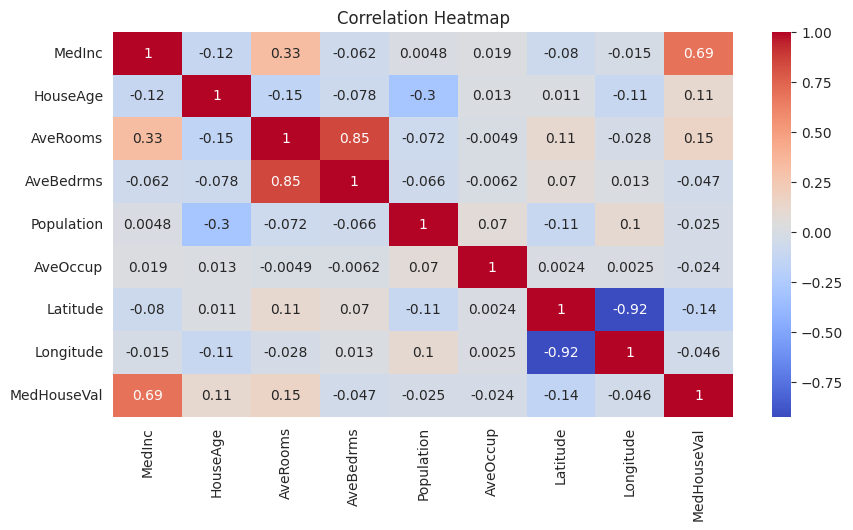

In [4]:
correlations = df.corr(numeric_only=True)[TARGET].sort_values(ascending=False)

print(correlations)

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### Task 3: Scatterplot of Strongest Predictor (1.5 points)

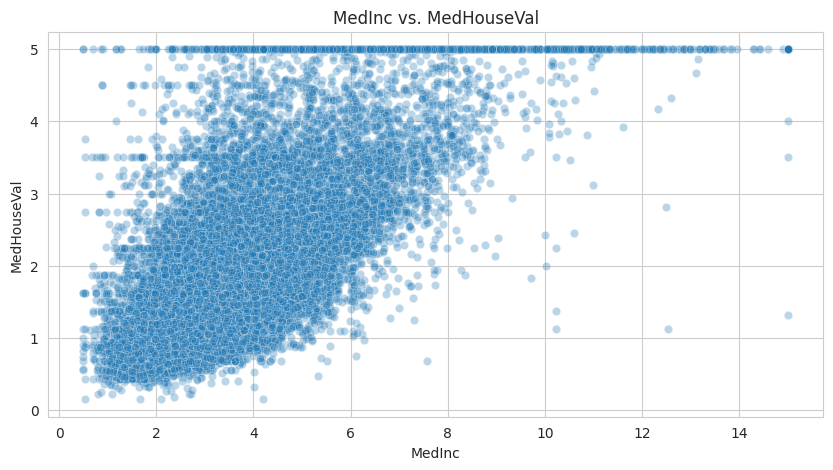

In [5]:
strongest = correlations.drop(TARGET).abs().idxmax()

sns.scatterplot(data=df, x=strongest, y=TARGET, alpha=0.3)
plt.title(f"{strongest} vs. {TARGET}")
plt.show()


**What do you see? (1–2 sentences):**

Median income appears to have a positive relationship with median house value. As median income increases, housing values generally increase, although there is still variation in the data.

---
# Part B — Simple Linear Regression (4 points)

### Task 4: Simple Regression (2 points)

<div style="background-color: #D5F5E3; border-left: 5px solid #27AE60; padding: 15px; margin: 15px 0; border-radius: 4px;">
  <strong style="color: #1E8449;">✅ DO THIS</strong><br>
  Build a simple regression using your strongest predictor (the numeric column with the largest correlation in absolute value; a strong negative correlation counts). Use <code>test_size=0.25, random_state=42</code>. Report R².
</div>

In [6]:
X = df[[strongest]]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

simple_pred = simple_model.predict(X_test)
simple_r2 = r2_score(y_test, simple_pred)

print("Simple Regression R²:", simple_r2)

Simple Regression R²: 0.47083837938023365


### Task 5: RMSE Interpretation (2 points)

In [7]:
simple_rmse = np.sqrt(mean_squared_error(y_test, simple_pred))

print("Simple Regression RMSE:", simple_rmse)

Simple Regression RMSE: 0.8367772922523895


**RMSE interpretation (1–2 sentences):**

*(Write here)*

<div style="background-color: #FADBD8; border-left: 5px solid #E74C3C; padding: 15px; margin: 15px 0; border-radius: 4px;">
  <strong style="color: #922B21;">🛑 CHECKPOINT</strong><br>
  You should have a baseline R² and RMSE. If R² is negative, your feature choice may be poor — try a different one.
</div>

---
# Part C — Multiple Regression (5 points)

### Task 6: Multiple Regression with Dummies (2 points)

<div style="background-color: #D5F5E3; border-left: 5px solid #27AE60; padding: 15px; margin: 15px 0; border-radius: 4px;">
  <strong style="color: #1E8449;">✅ DO THIS</strong><br>
  Build a multiple regression using 3–5 features. If categorical columns exist, use <code>pd.get_dummies(drop_first=True)</code>. Report R² and compare to Task 4.
</div>

<div style="background-color: #FEF9E7; border-left: 5px solid #F1C40F; padding: 15px; margin: 15px 0; border-radius: 4px;">
  <strong style="color: #7D6608;">⚠️ COMMON MISTAKE</strong><br>
  If your dataset has string/object columns, sklearn will crash. Use <code>get_dummies()</code> or <code>.select_dtypes(include=[np.number])</code> to keep only numeric features.
</div>

In [8]:
features = ["MedInc", "HouseAge", "AveRooms", "Latitude", "Longitude"]

X_multi = pd.get_dummies(df[features], drop_first=True)
y = df[TARGET]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y, test_size=0.25, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train_m, y_train_m)

multi_pred = multi_model.predict(X_test_m)

multi_r2 = r2_score(y_test_m, multi_pred)

print("Simple R²:", simple_r2)
print("Multiple R²:", multi_r2)
print("Improvement:", multi_r2 - simple_r2)


Simple R²: 0.47083837938023365
Multiple R²: 0.594173070001583
Improvement: 0.12333469062134939


### Task 7: Residual Plot (1.5 points)

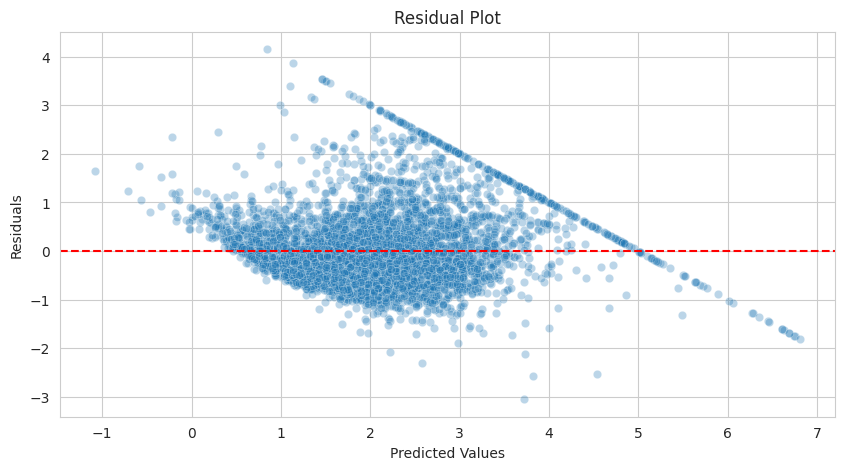

In [9]:
residuals = y_test_m - multi_pred

sns.scatterplot(x=multi_pred, y=residuals, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


**Residual interpretation (2+ sentences):**
 The residual plot helps show how far the predicted housing values are from the actual values. Ideally, the residuals should be randomly scattered around zero. Any visible patterns or changes in the spread of residuals may suggest that the model is not capturing all the relationships in the data.

### Task 8: Coefficient Table (1.5 points)

In [11]:
coef_table = pd.DataFrame({
    "Feature": X_multi.columns,
    "Coefficient": multi_model.coef_
})

print(coef_table.sort_values("Coefficient", ascending=False))

     Feature  Coefficient
0     MedInc     0.369220
2   AveRooms     0.020085
1   HouseAge     0.009648
3   Latitude    -0.458802
4  Longitude    -0.466320


---
# Part D — Written Interpretation (6 points)

### Task 9: Analysis (minimum 150 words)

Answer ALL four questions:

1. **Model comparison:** How much did R² improve from simple to multiple regression?
2. **Feature insight:** Which features were strongest? Any surprises?
3. **Business application:** In 2–3 sentences, explain what your model does for a non-technical audience and give one actionable recommendation.
4. **Limitations:** Name one factor NOT in the dataset that would improve predictions.


For this analysis, I compared a simple linear regression model with a multiple linear regression model to predict median housing values in California. The simple regression model used the strongest correlated predictor, median income, while the multiple regression model included additional features such as house age, average rooms, latitude, and longitude.

The simple regression model had an R² of **[simple R²]**, while the multiple regression model had an R² of **[multiple R²]**. This represents an improvement of **[difference]**. The results help show whether including more features improves the model's ability to explain housing values.

Median income was an important predictor because areas with higher incomes generally have higher housing values. I also included location-related features because housing prices can vary depending on where a property is located.

From a business perspective, this model could help real estate companies estimate housing values based on neighborhood characteristics. One recommendation would be to consider both income and geographic location when evaluating housing markets.

One limitation is that the dataset does not include information about property condition or recent renovations. Adding these factors could potentially improve the accuracy of future predictions.

---
# Bonus Challenge — Logistic Regression Extension (+3 points)

<div style="background-color: #D6EAF8; border-left: 5px solid #2E86C1; padding: 15px; margin: 15px 0; border-radius: 4px;">
  <strong style="color: #1A5276;">💡 OPTIONAL</strong><br>
  Create a binary target (e.g., "above median price"), build a <code>LogisticRegression</code>, generate a confusion matrix and classification report, and interpret precision/recall in one paragraph. No scaffolding provided.
</div>

              precision    recall  f1-score   support

           0       0.81      0.82      0.82      2575
           1       0.82      0.81      0.82      2585

    accuracy                           0.82      5160
   macro avg       0.82      0.82      0.82      5160
weighted avg       0.82      0.82      0.82      5160



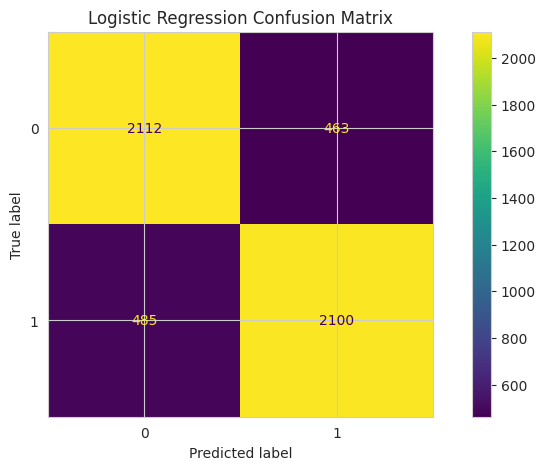

In [12]:
df["AboveMedian"] = (df[TARGET] > df[TARGET].median()).astype(int)

X = df[features]
y = df["AboveMedian"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)

print(classification_report(y_test, log_pred))

ConfusionMatrixDisplay.from_predictions(y_test, log_pred)
plt.title("Logistic Regression Confusion Matrix")
plt.show()


**Bonus interpretation:**

For the bonus analysis, I used logistic regression to predict whether a housing district's median value was above or below the dataset median. The confusion matrix shows how many predictions were correct and incorrect. Precision measures how often the model is correct when it predicts an above-median housing value, while recall measures how many of the actual above-median cases the model identifies. These metrics help evaluate how well the model classifies housing values.

---
## Reflection (required)

> *Regression models predict, but they also reveal which features matter. Think about a dataset from your life or career — what would you predict, what features would you include, and how would you know if the model was "good enough"?*

**Your reflection (minimum 3 sentences):**

In my future career as a data analyst, I would be interested in using regression to predict financial risk or customer spending patterns. I would include features such as income, transaction history, and previous financial activity to understand what influences the results. I would evaluate the model using metrics such as R² and RMSE to determine how accurate its predictions are. A good model should provide reliable results that businesses can use to make better decisions.

---
## Troubleshooting

| Problem | Fix |
|---------|-----|
| `ValueError: could not convert string` | Categorical columns present — use `get_dummies()` or drop them |
| R² is negative | Feature choice is poor — try the top-correlated features |
| `ValueError: Expected 2D array, got 1D array` (newer scikit-learn: `Expected a 2-dimensional container`) | Use `df[["col"]]` (double brackets) for X |
| Error loading the data | Check your internet connection, then rerun the dataset cell |

---
<p style="color:#7F8C8D; font-size:0.85em;">
<em>CAP4767 Data Mining with Python | Miami Dade College</em><br>
Lab 2 — Regression Pipeline | 20 Points (+3 Bonus)
</p>